In [1]:
# Predictive Maintenance System
# Industrial Rotating Equipment
# 48-Hour Failure Prediction

print("Predictive Maintenance Project Started!")
print("Goal: Predict machine failure within the next 48 hours.")

Predictive Maintenance Project Started!
Goal: Predict machine failure within the next 48 hours.


In [3]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# STEP 5 - Create Industrial Machine Sensor Dataset

import pandas as pd
import numpy as np

np.random.seed(42)

# Number of machines and readings
num_machines = 10
readings_per_machine = 500

data = []

for machine in range(1, num_machines + 1):

    for reading in range(readings_per_machine):

        vibration = np.random.normal(3.0, 0.7)
        temperature = np.random.normal(65, 5)
        pressure = np.random.normal(5, 0.5)
        motor_current = np.random.normal(10, 1.5)
        rpm = np.random.normal(1500, 80)
        acoustic = np.random.normal(60, 5)

        # Failure condition
        failure = 0

        if vibration > 4.5 and temperature > 72:
            failure = 1

        if motor_current > 13 and pressure < 4.3:
            failure = 1

        data.append([
            machine,
            reading,
            vibration,
            temperature,
            pressure,
            motor_current,
            rpm,
            acoustic,
            failure
        ])

df = pd.DataFrame(data, columns=[
    "Machine_ID",
    "Reading",
    "Vibration_mm_s",
    "Temperature_C",
    "Pressure_bar",
    "Motor_Current_A",
    "RPM",
    "Acoustic_dB",
    "Failure"
])

print("Dataset created successfully!")
print("Number of rows:", len(df))

df.head()

Dataset created successfully!
Number of rows: 5000


,Machine_ID,Reading,Vibration_mm_s,Temperature_C,Pressure_bar,Motor_Current_A,RPM,Acoustic_dB,Failure
0,1,0,3.347700,64.308678,5.323844,12.284545,1481.267730,58.829315,0
1,1,1,4.105449,68.837174,4.765263,10.813840,1462.926585,57.671351,0
2,1,2,3.169374,55.433599,4.137541,9.156569,1418.973510,61.571237,0
3,1,3,2.364383,57.938481,5.732824,9.661336,1505.402256,52.876259,0
4,1,4,2.618932,65.554613,4.424503,10.563547,1451.948905,58.541531,0


In [7]:
# STEP 6 - Dataset Analysis

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFailure Distribution:")
print(df["Failure"].value_counts())

print("\nFailure Percentage:")
print(df["Failure"].value_counts(normalize=True) * 100)

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape:
(5000, 9)

Column Names:
['Machine_ID', 'Reading', 'Vibration_mm_s', 'Temperature_C', 'Pressure_bar', 'Motor_Current_A', 'RPM', 'Acoustic_dB', 'Failure']

Missing Values:
Machine_ID         0
Reading            0
Vibration_mm_s     0
Temperature_C      0
Pressure_bar       0
Motor_Current_A    0
RPM                0
Acoustic_dB        0
Failure            0
dtype: int64

Failure Distribution:
Failure
0    4980
1      20
Name: count, dtype: int64

Failure Percentage:
Failure
0    99.6
1     0.4
Name: proportion, dtype: float64

Statistical Summary:


,Machine_ID,Reading,Vibration_mm_s,Temperature_C,Pressure_bar,Motor_Current_A,RPM,Acoustic_dB,Failure
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,5.500000,249.500000,3.001260,64.997186,4.999696,9.980179,1500.471855,60.022786,0.004000
std,2.872569,144.351715,0.710568,4.931232,0.499837,1.488552,80.989154,4.931180,0.063125
min,1.000000,0.000000,0.300537,48.352481,3.038800,4.467452,1193.067556,42.524774,0.000000
25%,3.000000,124.750000,2.513814,61.559702,4.665890,8.970419,1445.574966,56.727506,0.000000
50%,5.500000,249.500000,2.997314,65.010601,5.006128,9.990405,1500.538905,60.004689,0.000000
75%,8.000000,374.250000,3.493128,68.365115,5.336182,10.962445,1555.316116,63.303509,0.000000
max,10.000000,499.000000,5.298883,82.144552,6.805675,16.718626,1795.329960,79.711655,1.000000


In [8]:
# STEP 7 - Sensor Correlation Analysis

sensor_columns = [
    "Vibration_mm_s",
    "Temperature_C",
    "Pressure_bar",
    "Motor_Current_A",
    "RPM",
    "Acoustic_dB"
]

correlation_matrix = df[sensor_columns].corr()

print("Sensor Correlation Matrix:")
display(correlation_matrix)

Sensor Correlation Matrix:


,Vibration_mm_s,Temperature_C,Pressure_bar,Motor_Current_A,RPM,Acoustic_dB
Vibration_mm_s,1.000000,0.006487,-0.027867,-0.007710,0.002227,0.009323
Temperature_C,0.006487,1.000000,-0.012417,0.009670,0.008823,-0.001154
Pressure_bar,-0.027867,-0.012417,1.000000,-0.003333,0.008487,-0.006652
Motor_Current_A,-0.007710,0.009670,-0.003333,1.000000,-0.025224,-0.008899
RPM,0.002227,0.008823,0.008487,-0.025224,1.000000,0.016672
Acoustic_dB,0.009323,-0.001154,-0.006652,-0.008899,0.016672,1.000000


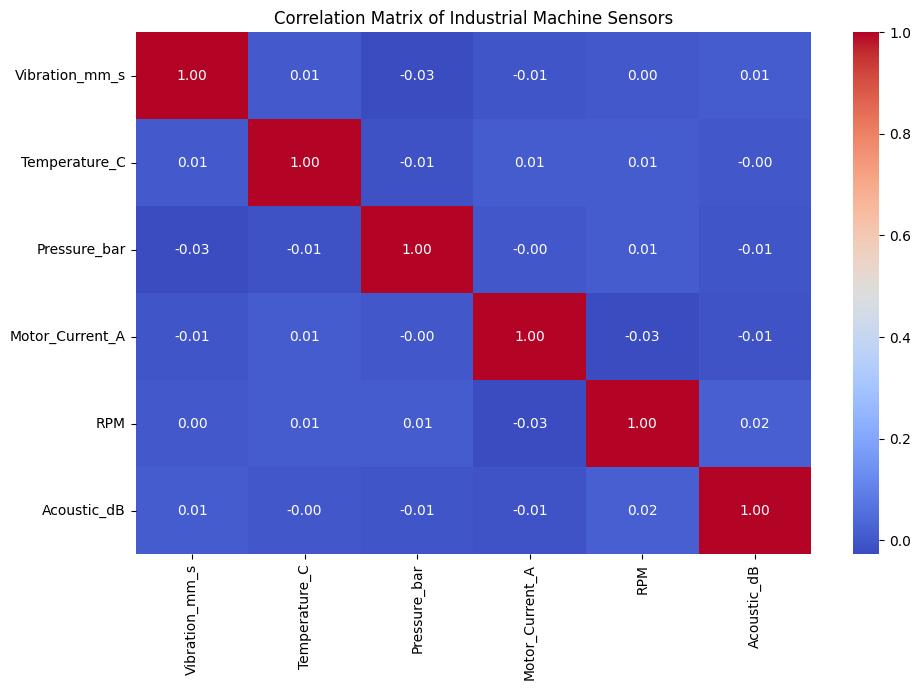

In [9]:
# Correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Industrial Machine Sensors")
plt.tight_layout()
plt.show()

In [10]:
# STEP 8 - Failure Distribution Analysis

failure_counts = df["Failure"].value_counts()

print("Failure Counts:")
print(failure_counts)

print("\nFailure Percentage:")
print((failure_counts / len(df) * 100).round(2))

Failure Counts:
Failure
0    4980
1      20
Name: count, dtype: int64

Failure Percentage:
Failure
0    99.6
1     0.4
Name: count, dtype: float64


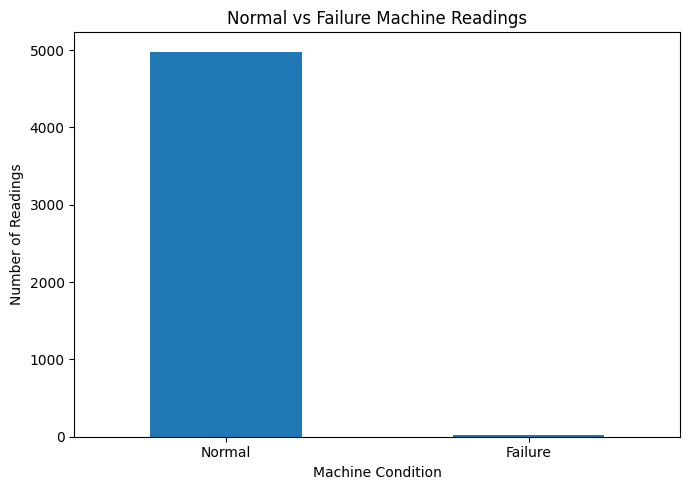

In [11]:
# Failure Distribution Graph

plt.figure(figsize=(7, 5))

failure_counts.plot(
    kind="bar",
    rot=0
)

plt.title("Normal vs Failure Machine Readings")
plt.xlabel("Machine Condition")
plt.ylabel("Number of Readings")
plt.xticks([0, 1], ["Normal", "Failure"])

plt.tight_layout()
plt.show()

In [12]:
# STEP 8.2 - Sensor Comparison

failure_summary = df.groupby("Failure")[[
    "Vibration_mm_s",
    "Temperature_C",
    "Pressure_bar",
    "Motor_Current_A",
    "RPM",
    "Acoustic_dB"
]].mean()

display(failure_summary)

,Vibration_mm_s,Temperature_C,Pressure_bar,Motor_Current_A,RPM,Acoustic_dB
Failure,,,,,,
0,2.999554,64.990038,5.002316,9.972382,1500.384186,60.028581
1,3.426085,66.777178,4.347201,11.921554,1522.301412,58.579685


In [13]:
# STEP 9 - Create 48-Hour Failure Prediction Label

df = df.sort_values(["Machine_ID", "Reading"]).reset_index(drop=True)

# Check the next 48 readings for each machine
df["Failure_Next_48H"] = (
    df.groupby("Machine_ID")["Failure"]
      .transform(
          lambda x: x.shift(-1)
                     .rolling(window=48, min_periods=1)
                     .max()
      )
      .fillna(0)
      .astype(int)
)

print("48-hour failure label created successfully!")

print("\nTarget Distribution:")
print(df["Failure_Next_48H"].value_counts())

display(
    df[
        [
            "Machine_ID",
            "Reading",
            "Failure",
            "Failure_Next_48H"
        ]
    ].head(20)
)

48-hour failure label created successfully!

Target Distribution:
Failure_Next_48H
0    4175
1     825
Name: count, dtype: int64


,Machine_ID,Reading,Failure,Failure_Next_48H
0,1,0,0,0
1,1,1,0,0
2,1,2,0,0
3,1,3,0,0
4,1,4,0,0
5,1,5,0,0
6,1,6,0,0
7,1,7,0,0
8,1,8,0,0
9,1,9,0,0


Normal within next 48 hours: 4175
Failure within next 48 hours: 825


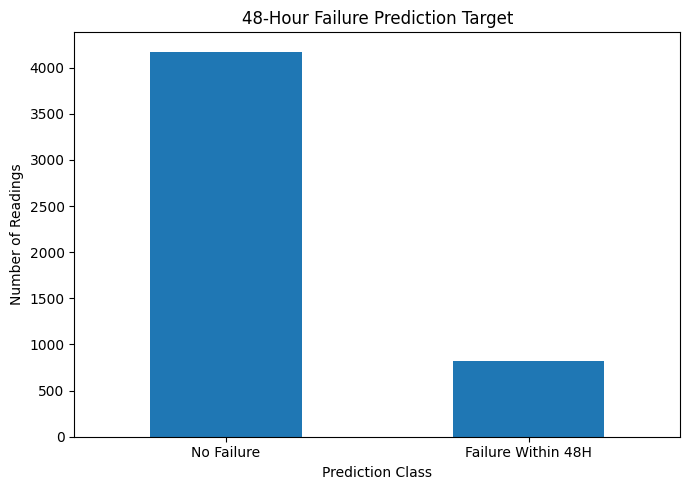

In [14]:
# 48-Hour Prediction Target Distribution

target_counts = df["Failure_Next_48H"].value_counts()

print("Normal within next 48 hours:", target_counts.get(0, 0))
print("Failure within next 48 hours:", target_counts.get(1, 0))

plt.figure(figsize=(7, 5))

target_counts.plot(kind="bar", rot=0)

plt.title("48-Hour Failure Prediction Target")
plt.xlabel("Prediction Class")
plt.ylabel("Number of Readings")
plt.xticks([0, 1], ["No Failure", "Failure Within 48H"])

plt.tight_layout()
plt.show()

In [15]:
# STEP 10 - Feature Engineering

sensor_columns = [
    "Vibration_mm_s",
    "Temperature_C",
    "Pressure_bar",
    "Motor_Current_A",
    "RPM",
    "Acoustic_dB"
]

# Sort machine readings correctly
df = df.sort_values(["Machine_ID", "Reading"]).reset_index(drop=True)

# Create 24-hour rolling features
for sensor in sensor_columns:

    df[f"{sensor}_Mean_24H"] = (
        df.groupby("Machine_ID")[sensor]
          .transform(lambda x: x.rolling(24, min_periods=1).mean())
    )

    df[f"{sensor}_Std_24H"] = (
        df.groupby("Machine_ID")[sensor]
          .transform(lambda x: x.rolling(24, min_periods=1).std())
    )

print("Feature engineering completed!")

print("\nNew dataset shape:")
print(df.shape)

display(df.head())

Feature engineering completed!

New dataset shape:
(5000, 22)


,Machine_ID,Reading,Vibration_mm_s,Temperature_C,Pressure_bar,Motor_Current_A,RPM,Acoustic_dB,Failure,Failure_Next_48H,...,Temperature_C_Mean_24H,Temperature_C_Std_24H,Pressure_bar_Mean_24H,Pressure_bar_Std_24H,Motor_Current_A_Mean_24H,Motor_Current_A_Std_24H,RPM_Mean_24H,RPM_Std_24H,Acoustic_dB_Mean_24H,Acoustic_dB_Std_24H
0,1,0,3.347700,64.308678,5.323844,12.284545,1481.267730,58.829315,0,0,...,64.308678,NaN,5.323844,NaN,12.284545,NaN,1481.267730,NaN,58.829315,NaN
1,1,1,4.105449,68.837174,4.765263,10.813840,1462.926585,57.671351,0,0,...,66.572926,3.202130,5.044554,0.394977,11.549192,1.039945,1472.097157,12.969148,58.250333,0.818804
2,1,2,3.169374,55.433599,4.137541,9.156569,1418.973510,61.571237,0,0,...,62.859817,6.818237,4.742216,0.593487,10.751651,1.564915,1454.389275,32.012602,59.357301,2.002836
3,1,3,2.364383,57.938481,5.732824,9.661336,1505.402256,52.876259,0,0,...,61.629483,6.086635,4.989868,0.692924,10.479072,1.389186,1467.142520,36.521029,57.737041,3.629767
4,1,4,2.618932,65.554613,4.424503,10.563547,1451.948905,58.541531,0,0,...,62.414509,5.555778,4.876795,0.651180,10.495967,1.203663,1464.103797,32.349781,57.897939,3.163993


In [16]:
# STEP 10.2 - Sensor Change Features

for sensor in sensor_columns:

    df[f"{sensor}_Change_6H"] = (
        df.groupby("Machine_ID")[sensor]
          .transform(lambda x: x - x.shift(6))
    )

print("6-hour sensor change features created!")

display(
    df[
        [
            "Machine_ID",
            "Reading",
            "Vibration_mm_s",
            "Vibration_mm_s_Mean_24H",
            "Vibration_mm_s_Std_24H",
            "Vibration_mm_s_Change_6H"
        ]
    ].head(15)
)

6-hour sensor change features created!


,Machine_ID,Reading,Vibration_mm_s,Vibration_mm_s_Mean_24H,Vibration_mm_s_Std_24H,Vibration_mm_s_Change_6H
0,1,0,3.347700,3.347700,NaN,NaN
1,1,1,4.105449,3.726574,0.535810,NaN
2,1,2,3.169374,3.540841,0.497028,NaN
3,1,3,2.364383,3.246726,0.714636,NaN
4,1,4,2.618932,3.121168,0.679598,NaN
5,1,5,2.578805,3.030774,0.646923,NaN
6,1,6,3.146205,3.047264,0.592166,-0.201495
7,1,7,2.919046,3.031237,0.550110,-1.186403
8,1,8,3.240533,3.054492,0.519289,0.071159
9,1,9,3.721700,3.121213,0.533118,1.357317


In [17]:
# STEP 11 - Prepare Data for Machine Learning

# All sensor-related features
feature_columns = []

for sensor in sensor_columns:
    feature_columns.append(sensor)
    feature_columns.append(f"{sensor}_Mean_24H")
    feature_columns.append(f"{sensor}_Std_24H")
    feature_columns.append(f"{sensor}_Change_6H")

X = df[feature_columns]
y = df["Failure_Next_48H"]

print("Number of ML features:", len(feature_columns))
print("X shape:", X.shape)
print("y shape:", y.shape)

Number of ML features: 24
X shape: (5000, 24)
y shape: (5000,)


In [18]:
# Handle Missing Values

imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(X)

print("Missing values handled successfully!")
print("Final feature shape:", X_imputed.shape)

Missing values handled successfully!
Final feature shape: (5000, 24)


In [19]:
# Chronological Train-Test Split

split_index = int(len(X_imputed) * 0.80)

X_train = X_imputed[:split_index]
X_test = X_imputed[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training failure rate:", round(y_train.mean() * 100, 2), "%")
print("Testing failure rate:", round(y_test.mean() * 100, 2), "%")

Training samples: 4000
Testing samples: 1000
Training failure rate: 19.42 %
Testing failure rate: 4.8 %


In [20]:
# STEP 12 - Train Random Forest Model

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [21]:
# STEP 12.1 - Make Predictions

y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

print("\nFirst 20 Predictions:")
print(y_pred[:20])

print("\nFirst 20 Failure Probabilities:")
print(y_probability[:20])

Predictions completed!

First 20 Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 Failure Probabilities:
[0.13691911 0.18108054 0.21505497 0.10027876 0.17715151 0.15805085
 0.23388763 0.22011161 0.21554758 0.16615843 0.23510171 0.20599745
 0.12357864 0.16777345 0.12459673 0.19504611 0.15592412 0.14586887
 0.12786166 0.12130538]


In [22]:
# STEP 12.2 - Model Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 88.3 %


In [23]:
# STEP 13 - Model Evaluation

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))
print("ROC-AUC  :", round(roc_auc, 3))

MODEL PERFORMANCE
-------------------------
Accuracy : 88.3 %
Precision: 0.144
Recall   : 0.292
F1 Score : 0.193
ROC-AUC  : 0.774


In [24]:
# Classification Report

print("Classification Report")
print("=====================")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Failure", "Failure Within 48H"],
        zero_division=0
    )
)

Classification Report
                    precision    recall  f1-score   support

        No Failure       0.96      0.91      0.94       952
Failure Within 48H       0.14      0.29      0.19        48

          accuracy                           0.88      1000
         macro avg       0.55      0.60      0.57      1000
      weighted avg       0.92      0.88      0.90      1000



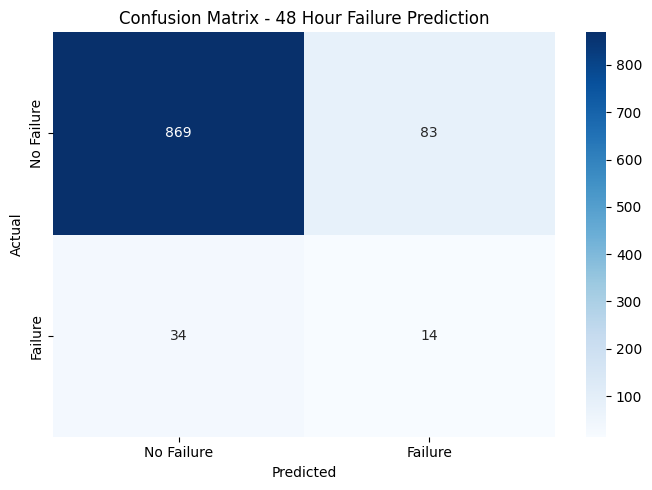

In [25]:
# STEP 13.3 - Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Confusion Matrix - 48 Hour Failure Prediction")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [26]:
# STEP 13.4 - Save Trained Model

joblib.dump(model, "predictive_maintenance_model.pkl")

print("Model saved successfully!")
print("File: predictive_maintenance_model.pkl")

Model saved successfully!
File: predictive_maintenance_model.pkl


In [27]:
# STEP 14 - Feature Importance Analysis

importance = pd.Series(
    model.feature_importances_,
    index=feature_columns
)

top_features = importance.sort_values(
    ascending=False
).head(15)

print("Top 15 Important Features:")
display(top_features)

Top 15 Important Features:


,0
Motor_Current_A_Std_24H,0.101566
Pressure_bar_Mean_24H,0.093544
Pressure_bar_Std_24H,0.078089
Acoustic_dB_Std_24H,0.076790
RPM_Mean_24H,0.072030
Temperature_C_Std_24H,0.065726
Motor_Current_A_Mean_24H,0.060398
Vibration_mm_s_Mean_24H,0.059728
Acoustic_dB_Mean_24H,0.056443
Temperature_C_Mean_24H,0.054962


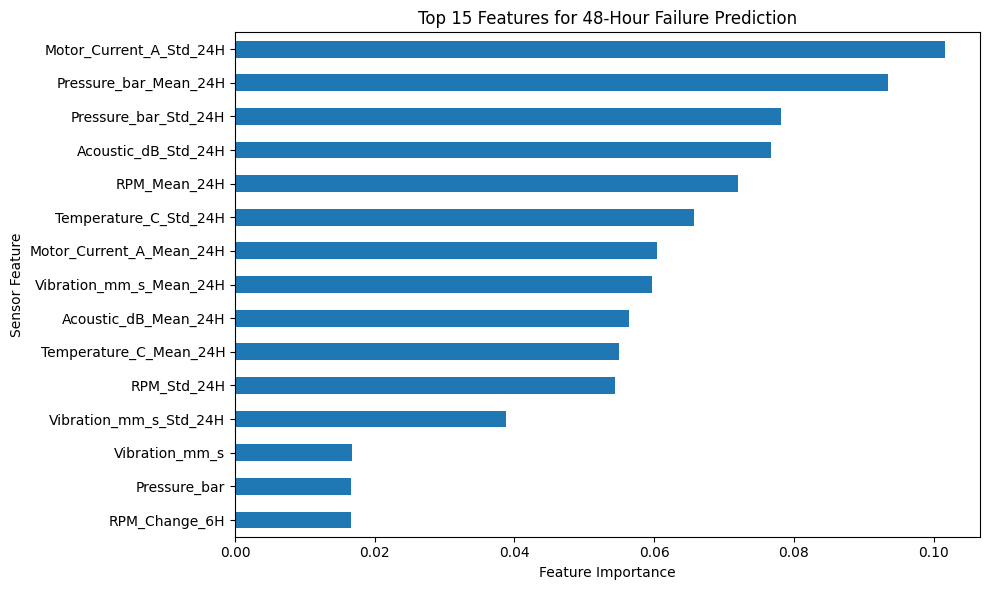

In [28]:
plt.figure(figsize=(10, 6))

top_features.sort_values().plot(kind="barh")

plt.title("Top 15 Features for 48-Hour Failure Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Sensor Feature")

plt.tight_layout()
plt.show()

In [29]:
# STEP 15 - 48 Hour Failure Prediction Demo

# Select one sample from test data
sample_index = 0

sample_data = X_test[sample_index].reshape(1, -1)

# Predict
prediction = model.predict(sample_data)[0]
probability = model.predict_proba(sample_data)[0][1]

print("========================================")
print("   INDUSTRIAL MACHINE HEALTH PREDICTION")
print("========================================")

print("Failure Probability:", round(probability * 100, 2), "%")

if prediction == 1:
    print("Prediction: FAILURE WITHIN 48 HOURS")
    print("Recommendation: Maintenance inspection required!")
else:
    print("Prediction: NO FAILURE WITHIN 48 HOURS")
    print("Recommendation: Machine condition is normal.")

print("========================================")

   INDUSTRIAL MACHINE HEALTH PREDICTION
Failure Probability: 13.69 %
Prediction: NO FAILURE WITHIN 48 HOURS
Recommendation: Machine condition is normal.


In [30]:
# STEP 16 - Save Final Dataset

df.to_csv(
    "predictive_maintenance_dataset.csv",
    index=False
)

print("Final dataset saved successfully!")
print("File: predictive_maintenance_dataset.csv")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Final dataset saved successfully!
File: predictive_maintenance_dataset.csv
Rows: 5000
Columns: 28


In [31]:
# Check saved dataset

import os

file_size = os.path.getsize(
    "predictive_maintenance_dataset.csv"
) / (1024 * 1024)

print("Dataset file size:", round(file_size, 2), "MB")

Dataset file size: 2.17 MB


In [32]:
# STEP 16 - Save Dataset as Excel File

df.to_excel(
    "predictive_maintenance_dataset.xlsx",
    index=False
)

print("Excel file created successfully!")
print("File: predictive_maintenance_dataset.xlsx")

Excel file created successfully!
File: predictive_maintenance_dataset.xlsx


In [33]:
from google.colab import files

files.download("predictive_maintenance_dataset.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import os

print(os.path.exists("predictive_maintenance_dataset.csv"))

True


In [35]:
import os

print("CSV exists:", os.path.exists("predictive_maintenance_dataset.csv"))

CSV exists: True


In [36]:
from google.colab import files

files.download("/content/predictive_maintenance_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
from google.colab import files

files.download("/content/predictive_maintenance_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
# STEP 17 - Save Model Performance Metrics

import json

metrics = {
    "Accuracy": round(accuracy, 4),
    "Precision": round(precision, 4),
    "Recall": round(recall, 4),
    "F1_Score": round(f1, 4),
    "ROC_AUC": round(roc_auc, 4)
}

with open("model_metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

print("Model metrics saved successfully!")
print(json.dumps(metrics, indent=4))

Model metrics saved successfully!
{
    "Accuracy": 0.883,
    "Precision": 0.1443,
    "Recall": 0.2917,
    "F1_Score": 0.1931,
    "ROC_AUC": 0.7744
}


In [39]:
from google.colab import files

files.download("/content/model_metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

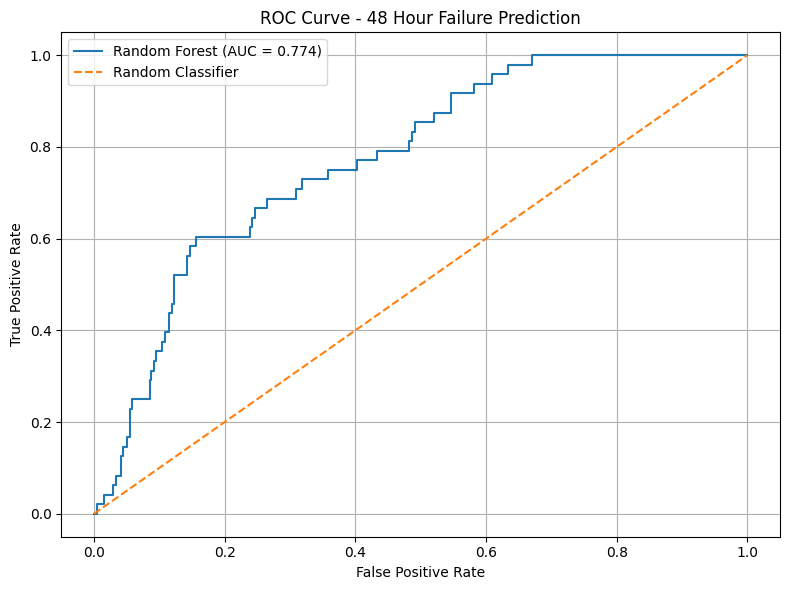

ROC-AUC: 0.774


In [40]:
# STEP 18 - ROC Curve

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_probability)
roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc_value:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - 48 Hour Failure Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc_value, 3))

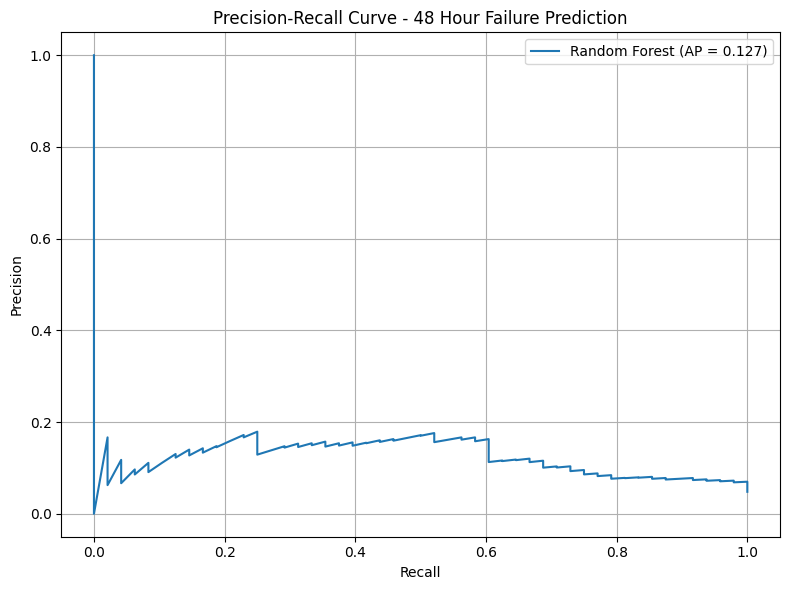

Average Precision: 0.127


In [41]:
# STEP 19 - Precision Recall Curve

from sklearn.metrics import precision_recall_curve, average_precision_score

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_test,
    y_probability
)

average_precision = average_precision_score(
    y_test,
    y_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Random Forest (AP = {average_precision:.3f})"
)

plt.title("Precision-Recall Curve - 48 Hour Failure Prediction")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Average Precision:", round(average_precision, 3))

In [42]:
# STEP 20 - Final Model Performance Summary

performance = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

performance["Score"] = performance["Score"].round(3)

display(performance)

print("\nFINAL MODEL PERFORMANCE")
print("========================")

for _, row in performance.iterrows():
    print(f"{row['Metric']:<10}: {row['Score']}")

,Metric,Score
0,Accuracy,0.883
1,Precision,0.144
2,Recall,0.292
3,F1 Score,0.193
4,ROC-AUC,0.774



FINAL MODEL PERFORMANCE
Accuracy  : 0.883
Precision : 0.144
Recall    : 0.292
F1 Score  : 0.193
ROC-AUC   : 0.774


In [43]:
# Save performance summary

performance.to_csv(
    "/content/model_performance_summary.csv",
    index=False
)

print("Performance summary saved successfully!")

Performance summary saved successfully!


In [44]:
# STEP 21 - Project Summary

project_summary = {
    "Project Title": "Predictive Maintenance System for Industrial Rotating Equipment",

    "Objective": (
        "To develop a machine learning system that predicts "
        "industrial machine failure within the next 48 hours "
        "using sensor data."
    ),

    "Machine Parameters": [
        "Vibration",
        "Temperature",
        "Pressure",
        "Motor Current",
        "RPM",
        "Acoustic Level"
    ],

    "Machine Learning Model": "Random Forest Classifier",

    "Prediction Target": "Failure Within Next 48 Hours",

    "Feature Engineering": [
        "24-hour rolling mean",
        "24-hour rolling standard deviation",
        "6-hour sensor change"
    ],

    "Evaluation Metrics": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
}

for key, value in project_summary.items():
    print(f"\n{key}:")
    print(value)


Project Title:
Predictive Maintenance System for Industrial Rotating Equipment

Objective:
To develop a machine learning system that predicts industrial machine failure within the next 48 hours using sensor data.

Machine Parameters:
['Vibration', 'Temperature', 'Pressure', 'Motor Current', 'RPM', 'Acoustic Level']

Machine Learning Model:
Random Forest Classifier

Prediction Target:
Failure Within Next 48 Hours

Feature Engineering:
['24-hour rolling mean', '24-hour rolling standard deviation', '6-hour sensor change']

Evaluation Metrics:
['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']


In [45]:
# STEP 22 - Create README.md

readme_content = """
# Predictive Maintenance System for Industrial Rotating Equipment

## Project Overview

This project develops a machine learning based predictive maintenance
system for industrial rotating equipment. The system analyzes machine
sensor parameters and predicts whether a machine failure may occur
within the next 48 hours.

## Objective

To predict industrial equipment failure 48 hours in advance using
machine sensor data and machine learning techniques.

## Sensor Parameters

- Vibration
- Temperature
- Pressure
- Motor Current
- RPM
- Acoustic Level

## Methodology

1. Generate and collect machine sensor data
2. Perform exploratory data analysis
3. Analyze sensor correlations
4. Create a 48-hour failure prediction target
5. Perform feature engineering
6. Handle missing values
7. Train a Random Forest classifier
8. Evaluate model performance
9. Analyze feature importance
10. Generate failure predictions

## Feature Engineering

The following features were created:

- 24-hour rolling mean
- 24-hour rolling standard deviation
- 6-hour sensor change

## Machine Learning Model

Random Forest Classifier

## Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix
- ROC Curve
- Precision-Recall Curve

## Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Joblib
- Google Colab

## Project Output

The system provides:

- 48-hour failure prediction
- Failure probability
- Machine condition classification
- Important sensor features
- Model performance analysis

## Project Goal

The proposed system can support predictive maintenance by identifying
potential machine failures before breakdown and helping maintenance
teams plan inspections and servicing.

## Author

Biomedical Engineering Student

"""

with open("/content/README.md", "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [46]:
from google.colab import files

files.download("/content/README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
# STEP 23 - Create requirements.txt

requirements = """
pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
openpyxl
"""

with open("/content/requirements.txt", "w") as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")
print(requirements)

requirements.txt created successfully!

pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
openpyxl



In [48]:
from google.colab import files

files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>